# 01 · Preprocessing — Pelka 2021 Colorectal Cancer (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven rule**, integrate
patients (Harmony), embed, remove detached islands, and split the manifold into its
transcriptional compartments. This is the largest dataset in the atlas
(~109k malignant cells across 64 tumours, four data groups), so every scale-sensitive
choice — PC count, Harmony strength, curve node count — is **re-derived on this
dataset**, not inherited from the smaller anchor runs. As in the reference runs the
manifold resolves into a **cycling** compartment and a **low-cycling (Embryonic)**
compartment; whether the trajectory is scoped to one or spans both is decided in 02
from the signature geography, not assumed here. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, time
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Pelka2021_Colorectal | category: Colorectal


### Load malignant compartment
Pelka et al. ship four data groups (each its own matrix + cell table, sharing one gene
list). We concatenate them and take their published `Malignant` calls. Expression is
UMI counts → `normalize_total` + `log1p` (loader).

In [3]:
ads = []
for g in ['Group1','Group2','Group3','Group4']:
    a = load_CCCA_adata(os.path.join(pth_in, g), verbose=False)
    a = a[a.obs.celltype == 'Malignant'].copy()
    ads.append(a); print(g, a.shape)
adata = ad.concat(ads, join='outer', merge='same'); adata.obs_names_make_unique(); del ads
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Group1 (22631, 43113)
Group2 (21459, 43113)
Group3 (26042, 43113)
Group4 (38867, 43113)
malignant: (108999, 43113) | samples: 64
expression: X max 8.47 (log1p of normalize_total counts)


### Sample thresholding — gap-rule guarded, atlas floor fallback
The house rule cuts at the largest **multiplicative cliff** in the sorted per-sample
counts. That rule assumes a clean count gap (calibration criterion C3). Here the 64
tumours' malignant counts fall off **smoothly** (7491 → 286, no cliff) so the largest
ratio sits at the very top of the distribution and the gap-rule degenerates to "keep one
sample". When the gap premise fails we fall back to the portable atlas floor (≥100 cells)
used across every prior run; the smallest tumour (286) already clears it, so all 64
samples are retained.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100
if gap == 0:
    print(f'gap at rank 0 -> no interior cliff; gap-rule ill-defined (C3 fails).')
    print(f'fallback: atlas min-cell floor >= {FLOOR}; smallest sample = {int(n.min())} cells')
    thresh = FLOOR
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [7491 4729 4601 4051 3723 2956 2780 2765 2654 2607 2387 2364 2235 2199
 2189 2142 2092 2038 2027 1994 1969 1951 1882 1876 1772 1764 1717 1554
 1517 1484 1431 1407 1375 1365 1260 1252 1241 1232 1200 1116 1100 1087
 1062 1030 1000  997  984  935  918  869  859  814  805  791  766  731
  650  635  570  561  461  370  329  286]
largest multiplicative gap: 7491 -> 4729 (ratio 1.58) at rank 0
gap at rank 0 -> no interior cliff; gap-rule ill-defined (C3 fails).
fallback: atlas min-cell floor >= 100; smallest sample = 286 cells
kept 64/64 samples -> 108999 cells


### Overdispersion, PCA, Harmony integration, embedding
`n_pcs=20` and UMAP `spread=1.3` follow the 10x precedents and are re-checked against the
scree here (cumulative variance is smooth; 20 PCs capture the structured signal before the
noise floor). `theta` is selected by a same-sample-neighbour-fraction sweep (lower = better
mixing; evaluated on a 20k-cell subsample for tractability at this scale): mixing is already
strong at theta=2 and barely moves through theta=10, so we take the strongest integration
that does not collapse structure (theta=10).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cumulative variance @ 20/30/40 PCs:', [round(vr[:k].sum(),3) for k in [20,30,40]])

# theta sweep: same-sample neighbour fraction (lower = better batch mixing)
from sklearn.neighbors import NearestNeighbors as _NN
rng = np.random.default_rng(SEED)
eval_idx = rng.choice(adata.n_obs, size=min(20000, adata.n_obs), replace=False)
s_all = adata.obs['sample'].values
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep[eval_idx], return_distance=False)[:,1:]
    se = s_all[eval_idx]
    return float(np.mean([(s_all[idx[i]]==se[i]).mean() for i in range(len(eval_idx))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()},
      '| random floor ~%.3f' % (1/adata.obs['sample'].nunique()))
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4556 over-dispersed features (0:00:22) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 4556
cumulative variance @ 20/30/40 PCs: [np.float64(0.38), np.float64(0.415), np.float64(0.441)]
same-sample neighbour fraction | pre-Harmony 0.714 | sweep {2: 0.107, 5: 0.105, 10: 0.104} | random floor ~0.016
selected theta = 10 (mixing plateaus; strongest integration without collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous body.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 20 cells in 9 detached islands


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the transcriptional compartments. We label them
*by biology*: the compartment with the **lowest cycling fraction** is the **Embryonic**
candidate; the rest are pooled as **Cycling/Metabolic**. `cell_cycle_phase` comes from the
publication's phase calls. Whether the trajectory is scoped to one lobe or spans both is
decided in 02 from the signature geography, not assumed here.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 54187, '2': 29412, '1': 25380}
cycling fraction per lobe: {'0': 0.439, '1': 0.082, '2': 0.077}
compartments: {'Cycling/Metabolic': 79567, 'Embryonic': 29412}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is
made on the regenerated embedding itself (not a scalar): the same-sample neighbour fraction
collapsed from ~0.71 (pre-Harmony) to ~0.10 (well below the pre-integration value, toward
the 1/64≈0.016 random floor given residual per-tumour CNV structure) and barely moved across theta 2→10, so integration is
robust rather than forced; the radius-graph left a single connected component. Tolerance:
Harmony's KMeans is not seed-deterministic, so the compartment sizes may shift by a few
hundred cells between runs — this does not change the Gate-1 call. The deliverable
`samples.pdf` follows.

64 samples share one continuous manifold; both compartments contain many samples.
Gate 1: samples intermixed on one continuous manifold -> PASS


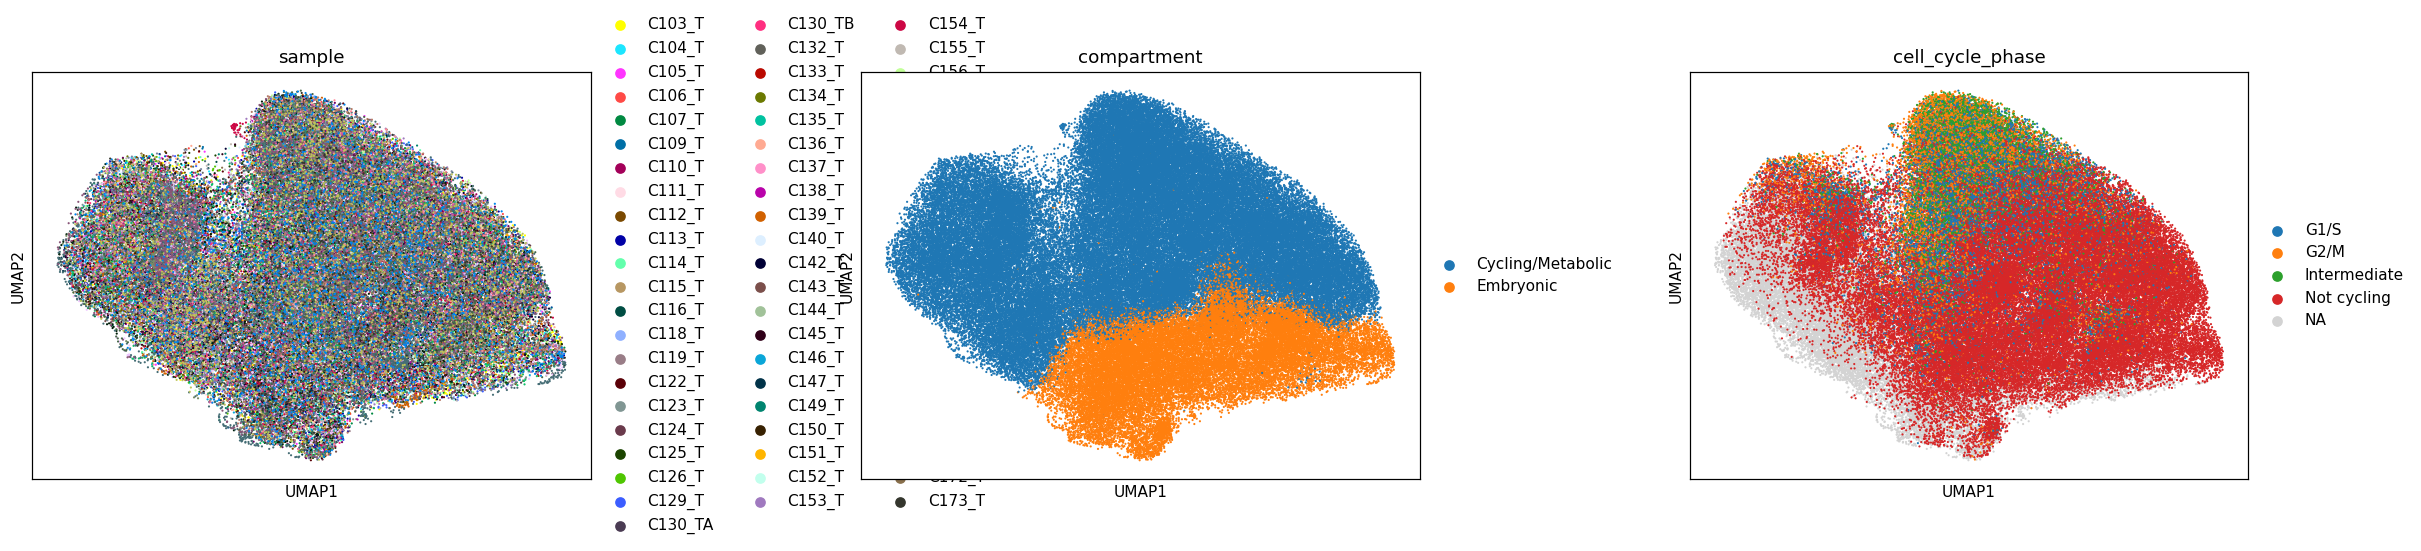

In [8]:
fig = sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'],
                 size=8, wspace=.35, show=False)
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; both compartments contain many samples.')
print('Gate 1: samples intermixed on one continuous manifold -> PASS')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (108979, 29856)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 108979


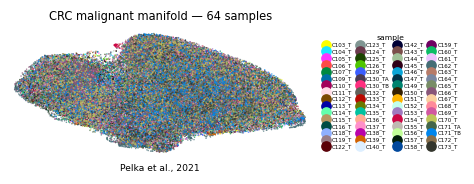

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip). Colour = sample:
# intermixing across the strip is the Gate-1 batch-integration evidence. The manifold is
# already horizontal in the raw embedding (orientation transform verified as the identity in
# 02), so X_umap_lin = raw_umap; direction is immaterial for this categorical panel. With 64
# tumours a per-sample legend is rendered in a compact multi-column block at the house font size.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=4, alpha=.7, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=4, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.1, labelspacing=.2, columnspacing=.4, fontsize=3.6, title='sample', title_fontsize=5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('CRC malignant manifold — 64 samples', size=7.5)
ax.text(.5, -.12, 'Pelka et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])